<a href="https://colab.research.google.com/github/maliksonmez/arnavutkoy-air-quality-forecast/blob/main/notebooks/04_external_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 — Dış veriyle keşifsel analiz (Ödev 1 geri bildirimi)

Girdi: `03_external_data.ipynb` çıktıları (`data/processed/`). Sorular:
1. CAMS istasyonu ne kadar tutturuyor? Saat dilimleri uyumlu mu?
2. Rüzgâr yönü kirliliği nasıl etkiliyor? Havalimanı (kuzeydoğu, ~7 km) yönünden esen rüzgâr kirli mi?
3. Sahra tozu günlerinde PM10 ne oluyor?

In [1]:
import os
import numpy as np
import pandas as pd

# Colab'da GitHub'dan, yerelde repodaki dosyadan okur.
DEPO = "https://github.com/maliksonmez/arnavutkoy-air-quality-forecast/raw/main/data/processed/"
YEREL = "../data/processed/"

def oku(ad):
    kaynak = YEREL + ad if os.path.exists(YEREL + ad) else DEPO + ad
    return pd.read_csv(kaynak, parse_dates=["tarih"], index_col="tarih").loc["2023-09-16":"2026-09-16"]

saatlik = oku("arnavutkoy_hourly_merged.csv")
gunluk = oku("arnavutkoy_daily_merged.csv")
kirleticiler = ["PM10", "PM2_5", "SO2", "NO2"]
print("Saatlik:", saatlik.shape, "| Günlük:", gunluk.shape)

import matplotlib.pyplot as plt
MAVI, TURUNCU, GRI = "#2a78d6", "#eb6834", "#e6e5e1"

Saatlik: (26328, 18) | Günlük: (1097, 28)


## 1. CAMS ile istasyonun karşılaştırması (günlük ortalamalar)

In [2]:
satirlar = []
for k in kirleticiler:
    ortak = gunluk[[f"{k}_ortalama", f"cams_{k}_ort"]].dropna()
    fark = ortak[f"cams_{k}_ort"] - ortak[f"{k}_ortalama"]
    satirlar.append({
        "Kirletici": k, "Gün": len(ortak),
        "İstasyon ort.": ortak[f"{k}_ortalama"].mean(),
        "CAMS ort.": ortak[f"cams_{k}_ort"].mean(),
        "CAMS / istasyon": ortak[f"cams_{k}_ort"].mean() / ortak[f"{k}_ortalama"].mean(),
        "MAE": fark.abs().mean(),
        "Korelasyon (r)": ortak.corr().iloc[0, 1],
    })
display(pd.DataFrame(satirlar).round(2))

,Kirletici,Gün,İstasyon ort.,CAMS ort.,CAMS / istasyon,MAE,Korelasyon (r)
0,PM10,1059,27.33,16.55,0.61,12.20,0.70
1,PM2_5,1044,14.92,11.24,0.75,6.32,0.55
2,SO2,1026,5.56,5.44,0.98,4.31,0.27
3,NO2,1048,24.33,7.87,0.32,16.55,0.63


**Yorum:** CAMS günden güne değişimi yakalıyor (r 0,55–0,70) ama seviyeyi düşük veriyor: PM10'un ~%61'i, NO2'nin yalnızca ~%32'si. SO2'de ilişki zayıf. Yerel düzeltme fikrinin gerekçesi bu tablo.

## 2. Saat dilimi kontrolü ve gün içi profil

,NO2,PM10,PM2_5
CAMS kaydırma (saat),,,
-4,0.469,0.507,0.404
-3,0.517,0.530,0.431
-2,0.560,0.550,0.457
-1,0.591,0.567,0.479
0,0.603,0.576,0.493
1,0.590,0.575,0.498
2,0.556,0.563,0.490
3,0.507,0.541,0.471
4,0.450,0.514,0.445


En yüksek korelasyonun kaydırması: {'NO2': 0, 'PM10': 0, 'PM2_5': 1}


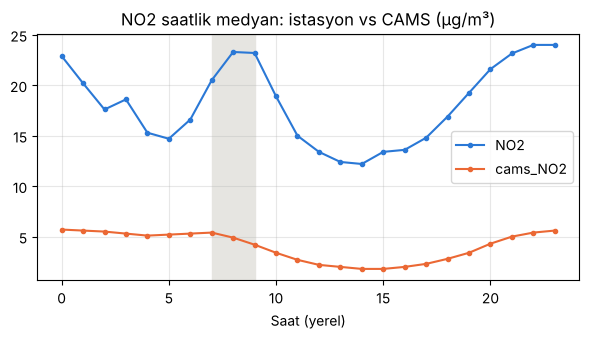

In [3]:
kaydirma = pd.DataFrame({
    k: {s: saatlik[k].corr(saatlik[f"cams_{k}"].shift(s)) for s in range(-4, 5)}
    for k in ["NO2", "PM10", "PM2_5"]
})
kaydirma.index.name = "CAMS kaydırma (saat)"
display(kaydirma.round(3))
print("En yüksek korelasyonun kaydırması:", kaydirma.idxmax().to_dict())

profil = saatlik.groupby(saatlik.index.hour)[["NO2", "cams_NO2"]].median()
ax = profil.plot(figsize=(7, 3.2), marker="o", ms=3, color=[MAVI, TURUNCU])
ax.axvspan(7, 9, color=GRI, zorder=0)
ax.set_title("NO2 saatlik medyan: istasyon vs CAMS (µg/m³)")
ax.set_xlabel("Saat (yerel)"); ax.grid(alpha=0.3)
plt.show()

**Yorum:** NO2 ve PM10'da en yüksek korelasyon 0 saat kaydırmada → iki kaynak da yerel saatte; A1'deki "saat dilimi doğrulanmadı" sınırlılığı kapandı. CAMS sabah 07–09 trafik zirvesini görmüyor; istasyonun katkısı tam burada.

## 3. Rüzgâr yönü ve havalimanı

In [4]:
# Havalimanının istasyondan yönü ve uzaklığı (yaklaşık terminal konumu)
ist, hl = (41.220937, 28.707547), (41.2753, 28.7519)
dy = (hl[0] - ist[0]) * 111.32
dx = (hl[1] - ist[1]) * 111.32 * np.cos(np.deg2rad(ist[0]))
print(f"Havalimanı: {np.degrees(np.arctan2(dx, dy)) % 360:.0f}° yönünde, {np.hypot(dx, dy):.1f} km")

yon = saatlik["met_wind_direction_10m"]
adlar = "N NNE NE ENE E ESE SE SSE S SSW SW WSW W WNW NW NNW".split()
sektor = pd.Categorical([adlar[i] for i in ((yon + 11.25) // 22.5 % 16).astype(int)], categories=adlar)
g = saatlik.groupby(sektor, observed=False)
display(pd.DataFrame({
    "saat payı (%)": g.size() / len(saatlik) * 100,
    "rüzgâr hızı (m/s)": g["met_wind_speed_10m"].mean(),
    "NO2 medyan": g["NO2"].median(), "PM10 medyan": g["PM10"].median(),
}).round(1))

Havalimanı: 32° yönünde, 7.1 km


,saat payı (%),rüzgâr hızı (m/s),NO2 medyan,PM10 medyan
N,9.7,4.1,13.1,17.8
NNE,16.4,4.2,16.2,18.0
NE,24.1,4.5,14.4,18.0
ENE,8.1,3.7,17.4,19.0
E,2.5,2.3,35.3,30.0
ESE,1.7,2.0,39.5,33.6
SE,1.8,2.1,47.5,34.9
SSE,2.2,2.5,55.2,41.1
S,5.2,3.2,46.7,39.8
SSW,10.6,4.6,22.6,31.0


In [5]:
# Grup karşılaştırması: hız ve mevsim etkisini ayırmak için sınıflara bölüyoruz
kuzey = (yon >= 348.75) | (yon < 56.25)          # N, NNE, NE: havalimanı sektörü
guneydogu = (yon >= 101.25) & (yon < 191.25)     # ESE, SE, SSE, S: yol ve kentsel alan yönü
grup = pd.Series(np.select([kuzey, guneydogu], ["N–NE (havalimanı)", "ESE–S"], "diğer"), index=saatlik.index)
hiz = pd.cut(saatlik["met_wind_speed_10m"], [0, 2, 4, 6, 20], labels=["0–2", "2–4", "4–6", ">6"])
mevsim = pd.Series(np.array(["kış", "ilkbahar", "yaz", "sonbahar"])[saatlik.index.month % 12 // 3], index=saatlik.index)

print("Saat payı (%):", (grup.value_counts(normalize=True) * 100).round(1).to_dict())
display(saatlik.groupby(grup)[["NO2", "PM10"]].median().round(1))

for k in ["NO2", "PM10"]:
    print(f"\n{k} medyan — rüzgâr hızına göre (m/s)")
    display(saatlik[k].groupby([grup, hiz], observed=False).median().unstack().round(1))
    print(f"{k} medyan — mevsime göre")
    display(saatlik[k].groupby([grup, mevsim]).median().unstack()[["kış", "ilkbahar", "yaz", "sonbahar"]].round(1))

Saat payı (%): {'N–NE (havalimanı)': 50.2, 'diğer': 38.9, 'ESE–S': 10.9}


,NO2,PM10
ESE–S,46.7,38.0
N–NE (havalimanı),14.8,18.0
diğer,18.0,24.1



NO2 medyan — rüzgâr hızına göre (m/s)


met_wind_speed_10m,0–2,2–4,4–6,>6
ESE–S,42.3,53.3,37.0,16.2
N–NE (havalimanı),28.4,18.5,13.3,10.4
diğer,29.7,22.9,14.0,10.0


NO2 medyan — mevsime göre


,kış,ilkbahar,yaz,sonbahar
ESE–S,50.5,50.1,35.0,44.8
N–NE (havalimanı),16.2,18.2,11.8,15.8
diğer,19.6,20.2,14.8,16.2



PM10 medyan — rüzgâr hızına göre (m/s)


met_wind_speed_10m,0–2,2–4,4–6,>6
ESE–S,34.8,41.8,35.0,24.0
N–NE (havalimanı),25.0,19.0,17.0,15.1
diğer,27.0,27.0,21.1,21.0


PM10 medyan — mevsime göre


,kış,ilkbahar,yaz,sonbahar
ESE–S,40.0,41.8,31.2,36.0
N–NE (havalimanı),14.9,21.0,17.0,20.9
diğer,24.2,28.4,20.0,23.1


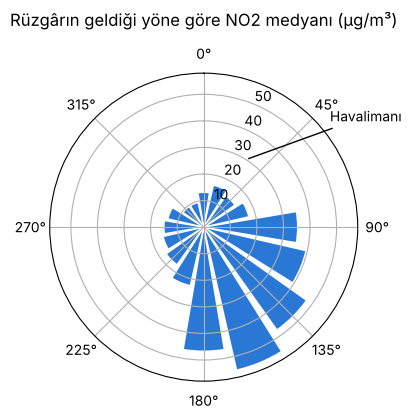

In [6]:
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(projection="polar")
medyan = saatlik.groupby(((yon + 11.25) // 22.5 % 16).astype(int))["NO2"].median().reindex(range(16))
ax.bar(np.deg2rad(np.arange(16) * 22.5), medyan.values, width=np.deg2rad(22.5) * 0.85, color=MAVI, edgecolor="white")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.annotate("Havalimanı", xy=(np.deg2rad(32), 30), xytext=(np.deg2rad(50), 62), arrowprops=dict(arrowstyle="-"))
ax.set_title("Rüzgârın geldiği yöne göre NO2 medyanı (µg/m³)", pad=14)
plt.show()

**Yorum:** Rüzgâr saatlerin yarısında N–NE'den (havalimanı yönü) esiyor ve bunlar **en temiz** saatler. ESE–S yönü (istasyonun yanındaki çok şeritli yol ve kentsel alan) seyrek ama yaklaşık 3 kat NO2, 2 kat PM10 getiriyor; bu fark her mevsimde ve her rüzgâr hızı sınıfında sürüyor. Bu istasyonda belirgin bir havalimanı etkisi görünmüyor. Modelde rüzgârın u/v bileşenleri ve günlük "ESE–S payı" girdi olarak kullanılıyor.

## 4. Sahra tozu günleri

In [7]:
ESIK = 20   # µg/m³, CAMS günlük ortalama toz; dağılımın ~%98'lik dilimi
toz = gunluk["cams_dust_ort"] > ESIK
print("Toz günü:", toz.sum())
olay = (toz != toz.shift()).cumsum()[toz]
olaylar = gunluk[toz].groupby(olay).agg(
    baslangic=("cams_dust_ort", lambda s: s.index.min().date()),
    gun=("cams_dust_ort", "size"),
    cams_toz_maks=("cams_dust_maks", "max"),
    pm10_ort_maks=("PM10_ortalama", "max"),
)
print("Olay sayısı:", len(olaylar))
display(olaylar.sort_values("cams_toz_maks", ascending=False).round(1))

oz = gunluk[["PM10_ortalama", "PM2_5_ortalama"]].assign(
    oran=gunluk["PM2_5_ortalama"] / gunluk["PM10_ortalama"],
    # ölçümü olmayan günler aşım hesabına girmez
    WHO_asim=(gunluk["PM10_ortalama"] > 45).astype(float).where(gunluk["PM10_ortalama"].notna()) * 100,
)
display(oz.groupby(toz.rename("toz günü")).agg(
    PM10_medyan=("PM10_ortalama", "median"), PM2_5_PM10_oran=("oran", "median"),
    WHO_asim_yuzde=("WHO_asim", "mean"), gun=("PM10_ortalama", "count"),
).round(2))

Toz günü: 20
Olay sayısı: 10


,baslangic,gun,cams_toz_maks,pm10_ort_maks
cams_dust_ort,,,,
8,2024-04-24,2,108.0,182.0
10,2024-05-28,2,58.0,54.9
6,2024-03-28,6,55.0,112.6
16,2025-03-15,2,45.0,41.3
20,2025-05-23,1,40.0,39.1
4,2023-11-04,1,36.0,58.9
14,2024-09-09,1,36.0,22.0
12,2024-09-05,2,30.0,49.2
18,2025-03-27,1,28.0,34.2


,PM10_medyan,PM2_5_PM10_oran,WHO_asim_yuzde,gun
toz günü,,,,
False,23.34,0.61,11.55,1039
True,63.98,0.44,65.00,20


**Yorum:** Toz günlerinde PM10 medyanı ~3 kat; PM2.5/PM10 oranı düşüyor (iri mineral parçacıklar) ve günlerin çoğu WHO PM10 eşiğini aşıyor. Olaylar çoğunlukla Mart–Mayıs'ta. CAMS toz tahmini, uyarı için doğrudan kullanılabilir bir girdi.